# Loan Default Risk Analysis

## Business Scenario

Imagine you work as a **Data Analyst for a financial company** that provides loans to customers.

The objective of company is to understand:


Who is more likely to default?

What customer *characteristics are associated with default?

Which types of loans have higher default rates?

How does credit history relate to default?

How much loan exposure is associated with risky customers?

**Company want some data-driven business recommendations.**


### Project Workflow

1. Data Understanding
2. Data Quality Checks
3. Data Cleaning
4. Exploratory Data Analysis (EDA)
5. Key Findings
6. Business Recommendations

>

## 1. Data Understanding

Load the dataset and inspect its structure before making any changes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize



In [98]:
df = pd.read_csv("loan_dataset.csv")
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


### Initial Missing-Value Check

In [4]:
df.isna().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


### Duplicate Check

In [5]:
df.duplicated().sum()

np.int64(165)

## 2. Initial Data Preparation

Rename a few columns to shorter, easier-to-read names for analysis.

In [6]:
df = df.rename(columns={"person_age":"age",
                "person_income":"income",
                "person_home_ownership":"home_ownership"})

In [7]:
df.columns

Index(['age', 'income', 'home_ownership', 'person_emp_length', 'loan_intent',
       'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status',
       'loan_percent_income', 'cb_person_default_on_file',
       'cb_person_cred_hist_length'],
      dtype='object')

## 3. Data Quality Checks

Check for obvious invalid or suspicious values before handling missing data.

The goal here is to identify **real data-quality issues**, not to investigate every extreme value unnecessarily.

In [8]:
df.query("age < 21 and age > 90")

,age,income,home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length


In [9]:
df[df['income'] <= 0]

,age,income,home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length


In [10]:
df['income'].min()

4000

In [11]:
df['income'].max()

6000000

In [12]:
df['income'].mean()

np.float64(66074.84846996715)

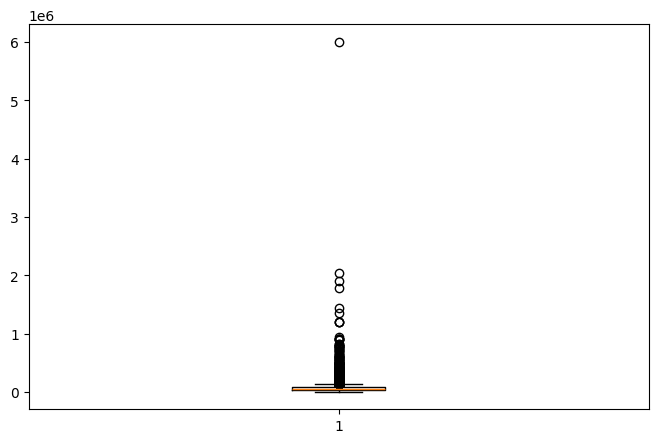

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(df["income"])
plt.show()


In [14]:
(df['person_emp_length'] <= 0).sum()

np.int64(4105)

In [15]:
df[df["loan_amnt"]<=0]

,age,income,home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length


In [16]:
df['loan_amnt'].max()

35000

In [17]:
df[df["loan_int_rate"]<=0]

,age,income,home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length


In [18]:
df['loan_int_rate'].max()

23.22

In [19]:
df["home_ownership"].unique()

array(['RENT', 'OWN', 'MORTGAGE', 'OTHER'], dtype=object)

In [20]:
df["loan_intent"].unique()

array(['PERSONAL', 'EDUCATION', 'MEDICAL', 'VENTURE', 'HOMEIMPROVEMENT',
       'DEBTCONSOLIDATION'], dtype=object)

## 4. Create the Clean Working Dataset

Create `df` by removing duplicate rows.

In [21]:
df = df.drop_duplicates()

In [22]:
df.duplicated().sum()

np.int64(0)

## 5. Handle Missing `person_emp_length`

Missing employment length does not automatically mean zero years of employment.

We first check whether missingness appears to differ across a few relevant borrower and loan characteristics. If there is no reliable rule for reconstructing the values, median imputation is used.

In [23]:
df["person_emp_length"].isna().sum()

np.int64(887)

checking of missingness is random or not

In [24]:
df["emp_length_missing"]=df["person_emp_length"].isna()

In [25]:
print(
    df.groupby("emp_length_missing")["age"].agg(["count", "mean", "median", "min", "max"])
)

                    count       mean  median  min  max
emp_length_missing                                    
False               31529  27.759238    26.0   20  144
True                  887  27.312289    25.0   21   70


In [26]:
home_ownership = pd.crosstab(
    df["home_ownership"],
    df["emp_length_missing"],
    normalize="columns"
) * 100

print(home_ownership)

emp_length_missing      False      True 
home_ownership                          
MORTGAGE            41.298487  39.233371
OTHER                0.336198   0.000000
OWN                  7.583495  19.391206
RENT                50.781820  41.375423


In [27]:
loan_grade = pd.crosstab( df["loan_grade"],
                         df["emp_length_missing"],
                          normalize = "columns") * 100

print(loan_grade)

emp_length_missing      False      True 
loan_grade                              
A                   32.671509  45.321308
B                   32.110121  29.650507
C                   19.991119  15.219842
D                   11.259475   7.891770
E                    3.016271   1.352875
F                    0.748517   0.563698
G                    0.202988   0.000000


In [28]:
loan_intent = pd.crosstab(
    df["loan_intent"],
    df["emp_length_missing"],
    normalize="columns"
) * 100

print(loan_intent)

emp_length_missing      False      True 
loan_intent                             
DEBTCONSOLIDATION   15.997970  16.347238
EDUCATION           19.816677  18.376550
HOMEIMPROVEMENT     11.097720  10.710259
MEDICAL             18.614609  19.503946
PERSONAL            16.962162  16.910936
VENTURE             17.510863  18.151071


In [29]:
print(
    df.groupby("emp_length_missing")["income"].agg(["count", "mean", "median", "min", "max"])
)

                    count          mean   median   min      max
emp_length_missing                                             
False               31529  66704.465254  56000.0  4000  6000000
True                  887  44308.392334  36000.0  4200   648000


In [30]:
default_rate = (
    df.groupby("emp_length_missing")["loan_status"].agg(["count", "mean"])
)

default_rate["default_rate_%"] = default_rate["mean"] * 100

print(default_rate)

                    count      mean  default_rate_%
emp_length_missing                                 
False               31529  0.215928       21.592819
True                  887  0.316798       31.679820


### Inspect Employment-Length Values

Check the distribution for unusual values before imputing missing values.

In [31]:
df["person_emp_length"].value_counts()

,count
person_emp_length,
0.0,4086
2.0,3832
3.0,3442
5.0,2926
1.0,2897
4.0,2863
6.0,2652
7.0,2186
8.0,1676


In [32]:
df[df["person_emp_length"] == 123]


,age,income,home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,emp_length_missing
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3,False
210,21,192000,MORTGAGE,123.0,VENTURE,A,20000,6.54,0,0.10,N,4,False


In [33]:
df[df["person_emp_length"] > 30][
    ["age", "person_emp_length"]
].sort_values("person_emp_length", ascending=False)

,age,person_emp_length
0,22,123.0
210,21,123.0
32355,78,41.0
32515,53,38.0
32428,58,34.0
31867,46,31.0
31866,47,31.0
30914,48,31.0
32263,46,31.0


### Correct the Suspicious Employment-Length Value

A value of `123` years is not realistic for this dataset, so it is treated as missing before imputation.

In [34]:
df.loc[
    df["person_emp_length"] == 123,
    "person_emp_length"
] = np.nan

### Median Imputation for Employment Length

In [35]:
df["person_emp_length"] = df["person_emp_length"].fillna(
    df["person_emp_length"].median()
)

In [36]:
print("Missing:", df["person_emp_length"].isna().sum())
print("Median:", df["person_emp_length"].median())

Missing: 0
Median: 4.0


## 6. Handle Missing `loan_int_rate`

There are missing interest-rate values. Before filling them, check whether missingness is associated with basic loan characteristics.

Because interest rates vary by loan grade, the final imputation uses the **median interest rate within each loan grade**.

In [37]:
df.isna().sum().sort_values(ascending=False)

,0
loan_int_rate,3095
income,0
home_ownership,0
person_emp_length,0
age,0
loan_intent,0
loan_grade,0
loan_amnt,0
loan_status,0
loan_percent_income,0


In [38]:
df["int_rate_missing"] =df["loan_int_rate"].isna().astype(int)

In [39]:
print(
    df.groupby("int_rate_missing")["income"].agg(["count", "mean", "median"])
)

                  count          mean   median
int_rate_missing                              
0                 29321  66029.759899  55000.0
1                  3095  66677.880129  56000.0


In [40]:
print(
    df.groupby("int_rate_missing")["loan_amnt"].agg(["count", "mean", "median"])
)

                  count         mean  median
int_rate_missing                            
0                 29321  9587.635142  8000.0
1                  3095  9652.681745  8000.0


In [41]:
print(
    df.groupby("int_rate_missing")["loan_status"].agg(["count", "mean"])
)

                  count      mean
int_rate_missing                 
0                 29321  0.219911
1                  3095  0.207108


In [42]:
print(
    pd.crosstab(
        df["loan_grade"],
        df["int_rate_missing"],
        normalize="columns"
    ) * 100
)

int_rate_missing          0          1
loan_grade                            
A                 33.126428  31.987076
B                 31.844071  33.925687
C                 19.811739  20.323102
D                 11.285427  10.048465
E                  3.001262   2.681745
F                  0.729852   0.872375
G                  0.201221   0.161551


In [43]:
df.dtypes

,0
age,int64
income,int64
home_ownership,object
person_emp_length,float64
loan_intent,object
loan_grade,object
loan_amnt,int64
loan_int_rate,float64
loan_status,int64
loan_percent_income,float64


## 7. Final Data Quality Checks

Perform a focused set of checks for invalid values, impossible relationships, duplicates, and extreme observations.

In [44]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [45]:
df[df["age"] > 100][
    ["age", "person_emp_length"]
]

,age,person_emp_length
81,144,4.0
183,144,4.0
575,123,2.0
747,123,7.0
32297,144,12.0


In [46]:
df[df["person_emp_length"] < 0]

,age,income,home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,emp_length_missing,int_rate_missing


In [47]:
df[df["loan_amnt"] <= 0]

,age,income,home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,emp_length_missing,int_rate_missing


In [48]:
df[df["income"] <= 0]

,age,income,home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,emp_length_missing,int_rate_missing


In [49]:
df[df["loan_int_rate"] <= 0]

,age,income,home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,emp_length_missing,int_rate_missing


In [50]:
df[df["loan_percent_income"] < 0]

,age,income,home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,emp_length_missing,int_rate_missing


In [51]:
df["home_ownership"].unique()


array(['RENT', 'OWN', 'MORTGAGE', 'OTHER'], dtype=object)

In [52]:
df["loan_grade"].unique()

array(['D', 'B', 'C', 'A', 'E', 'F', 'G'], dtype=object)

In [53]:
df["loan_intent"].unique()


array(['PERSONAL', 'EDUCATION', 'MEDICAL', 'VENTURE', 'HOMEIMPROVEMENT',
       'DEBTCONSOLIDATION'], dtype=object)

In [54]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,32416.0,27.747008,6.354100,20.00,23.00,26.00,30.00,144.00
income,32416.0,66091.640826,62015.580269,4000.00,38542.00,55000.00,79218.00,6000000.00
person_emp_length,32416.0,4.761538,3.983588,0.00,2.00,4.00,7.00,41.00
loan_amnt,32416.0,9593.845632,6322.730241,500.00,5000.00,8000.00,12250.00,35000.00
loan_int_rate,29321.0,11.017265,3.241680,5.42,7.90,10.99,13.47,23.22
loan_status,32416.0,0.218688,0.413363,0.00,0.00,0.00,0.00,1.00
loan_percent_income,32416.0,0.170250,0.106812,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32416.0,5.811297,4.059030,2.00,3.00,4.00,8.00,30.00
int_rate_missing,32416.0,0.095478,0.293878,0.00,0.00,0.00,0.00,1.00


### Fix Invalid Age Values

Age values above 100 are treated as missing and then imputed using the median age.

In [55]:
df.loc[
    df["age"] > 100,
    "age"
] = np.nan

### Review Extreme Income Values

Extreme income values are reviewed rather than automatically deleted. A large value is not necessarily an error.

In [56]:
df.nlargest(
    20, "income"
)[
    ["age", "income", "loan_amnt", "loan_percent_income"]
]

,age,income,loan_amnt,loan_percent_income
32297,NaN,6000000,5000,0.00
30049,42.0,2039784,8450,0.00
32546,60.0,1900000,1500,0.00
32497,63.0,1782000,12025,0.01
31924,44.0,1440000,6400,0.00
31922,47.0,1362000,6600,0.00
17833,32.0,1200000,12000,0.01
29119,36.0,1200000,10000,0.01
29120,40.0,1200000,10000,0.01
17834,34.0,948000,2000,0.00


In [58]:
df[
    df["person_emp_length"] > df["age"]
][
    ["age", "person_emp_length"]
]

,age,person_emp_length


In [60]:
df[
    df["cb_person_cred_hist_length"] > df["age"]
][
    ["age", "cb_person_cred_hist_length"]
]

,age,cb_person_cred_hist_length


### Check `loan_percent_income`

Temporarily compare the provided loan-to-income percentage with a calculated value. This is a validation check only; the temporary calculated column is not kept in the final dataset.

In [61]:
df["calculated_loan_percent_income"] = (
    df["loan_amnt"] / df["income"]
)


In [62]:
df.drop(
    columns=["calculated_loan_percent_income"],
    inplace=True,
    errors="ignore"
)

### Complete Missing-Value Imputation

Fill the remaining missing age values with the median and missing interest rates with the median within each loan grade.

In [65]:
df["age"] = df["age"].fillna(
    df["age"].median()
)

In [67]:
df["loan_int_rate"] = (
    df.groupby("loan_grade")["loan_int_rate"].transform(lambda x: x.fillna(x.median()))
)

### Final Validation

Confirm the cleaned dataset size and check the main variables after cleaning.

In [68]:
df.shape

(32416, 14)

# 8. Exploratory Data Analysis (EDA)

Now that the data is clean, move from **data quality** to **understanding the business patterns**.

The EDA is intentionally focused on questions relevant to loan default risk.

## 8.1 Borrower Profile

Understand who is receiving loans.

In [69]:
df["age"].describe()

,age
count,32416.000000
mean,27.730102
std,6.210006
min,20.000000
25%,23.000000
50%,26.000000
75%,30.000000
max,94.000000


In [70]:
df["income"].describe()

,income
count,3.241600e+04
mean,6.609164e+04
std,6.201558e+04
min,4.000000e+03
25%,3.854200e+04
50%,5.500000e+04
75%,7.921800e+04
max,6.000000e+06


In [71]:
df["home_ownership"].value_counts()

,count
home_ownership,
RENT,16378
MORTGAGE,13369
OWN,2563
OTHER,106


## 8.2 Loan Profile

Understand why loans are taken, their risk grades, amounts, interest rates, and credit-history length.

In [72]:
df["loan_intent"].value_counts()

,count
loan_intent,
EDUCATION,6411
MEDICAL,6042
VENTURE,5682
PERSONAL,5498
DEBTCONSOLIDATION,5189
HOMEIMPROVEMENT,3594


In [73]:
df["loan_intent"].value_counts(normalize=True) * 100

,proportion
loan_intent,
EDUCATION,19.777270
MEDICAL,18.638944
VENTURE,17.528381
PERSONAL,16.960760
DEBTCONSOLIDATION,16.007527
HOMEIMPROVEMENT,11.087117


In [74]:
df["loan_grade"].value_counts().sort_index()

,count
loan_grade,
A,10703
B,10387
C,6438
D,3620
E,963
F,241
G,64


In [75]:
df["loan_amnt"].describe()

,loan_amnt
count,32416.000000
mean,9593.845632
std,6322.730241
min,500.000000
25%,5000.000000
50%,8000.000000
75%,12250.000000
max,35000.000000


In [76]:
df["loan_int_rate"].describe()

,loan_int_rate
count,32416.000000
mean,11.020159
std,3.213380
min,5.420000
25%,7.880000
50%,10.990000
75%,13.480000
max,23.220000


In [77]:
df["cb_person_cred_hist_length"].describe()

,cb_person_cred_hist_length
count,32416.000000
mean,5.811297
std,4.059030
min,2.000000
25%,3.000000
50%,4.000000
75%,8.000000
max,30.000000


## 8.3 Overall Default Rate

Establish the baseline default rate before comparing different borrower and loan groups.

In [78]:
df["loan_status"].value_counts(normalize=True) * 100

,proportion
loan_status,
0,78.13117
1,21.86883


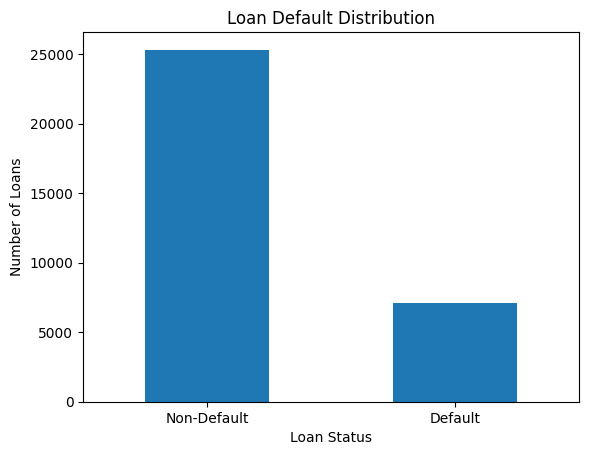

In [79]:
df["loan_status"].value_counts().plot(
    kind="bar"
)

plt.xlabel("Loan Status")
plt.ylabel("Number of Loans")
plt.title("Loan Default Distribution")
plt.xticks([0, 1], ["Non-Default", "Default"], rotation=0)
plt.show()

## 8.4 Default Rate by Loan Grade

Compare the observed default rate across loan grades.

In [82]:
df.groupby("loan_grade")["loan_status"].mean() * 100

,loan_status
loan_grade,
A,9.959824
B,16.318475
C,20.751786
D,59.060773
E,64.485981
F,70.539419
G,98.437500


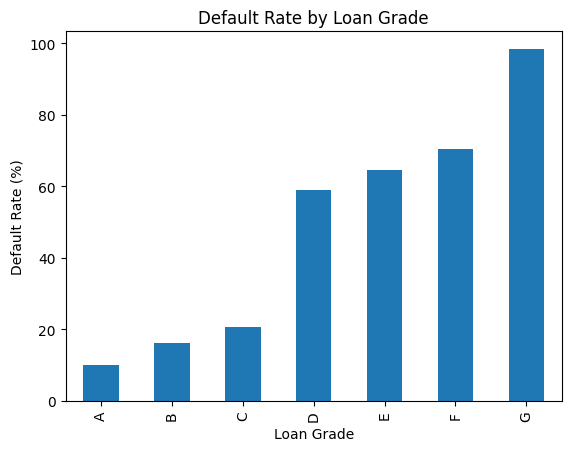

In [83]:

df.groupby("loan_grade")["loan_status"].mean().mul(100).plot(
    kind="bar"
)

plt.xlabel("Loan Grade")
plt.ylabel("Default Rate (%)")
plt.title("Default Rate by Loan Grade")
plt.show()

## 8.5 Default Rate by Loan Intent

Compare default rates across the main reasons for taking a loan.

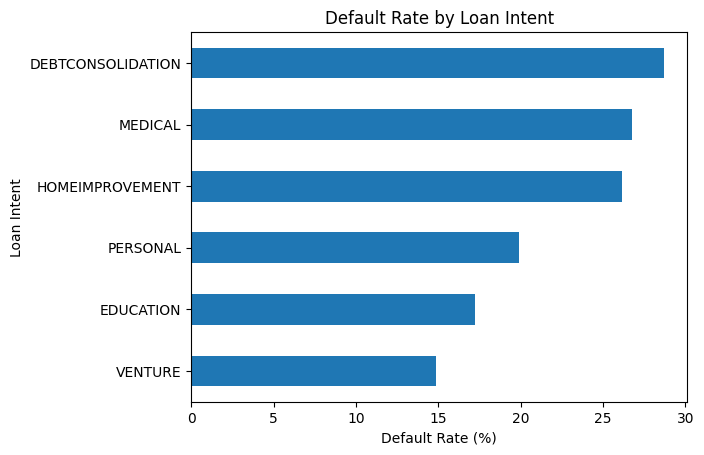

In [84]:
df.groupby("loan_intent")["loan_status"].mean().mul(100).sort_values().plot(
    kind="barh"
)

plt.xlabel("Default Rate (%)")
plt.ylabel("Loan Intent")
plt.title("Default Rate by Loan Intent")
plt.show()

In [85]:
df.groupby("loan_intent")["loan_status"].mean().mul(100).sort_values(ascending=False)

,loan_status
loan_intent,
DEBTCONSOLIDATION,28.676045
MEDICAL,26.762661
HOMEIMPROVEMENT,26.154702
PERSONAL,19.898145
EDUCATION,17.251599
VENTURE,14.853925


## 8.6 Default Rate by Home Ownership

Compare observed default rates across home-ownership categories.

In [86]:
df.groupby("home_ownership")["loan_status"].mean().mul(100).sort_values(ascending=False)

,loan_status
home_ownership,
RENT,31.609476
OTHER,31.132075
MORTGAGE,12.618745
OWN,7.491221


## 8.7 Default Rate by Loan-to-Income Ratio

Group borrowers by the proportion of income represented by the loan and compare default rates.

In [87]:
df["loan_income_group"] = pd.cut(
    df["loan_percent_income"],
    bins=[0, 0.10, 0.20, 0.30, 0.40, 1],
    labels=[
        "0-10%",
        "10-20%",
        "20-30%",
        "30-40%",
        "40%+"
    ],
    include_lowest=True
)

In [88]:
df.groupby("loan_income_group", observed=True)["loan_status"].mean().mul(100)

,loan_status
loan_income_group,
0-10%,11.754554
10-20%,15.126261
20-30%,22.016861
30-40%,68.888889
40%+,74.173369


## 8.8 Default Rate by Interest Rate

Group loans by interest-rate range and compare observed default rates.

In [89]:
df["interest_rate_group"] = pd.cut(
    df["loan_int_rate"],
    bins=[0, 8, 12, 16, 20, 25],
    labels=[
        "0-8%",
        "8-12%",
        "12-16%",
        "16-20%",
        "20%+"
    ],
    include_lowest=True
)

In [90]:
df.groupby(
    "interest_rate_group",
    observed=True
)["loan_status"].mean().mul(100)

,loan_status
interest_rate_group,
0-8%,9.363759
8-12%,15.904485
12-16%,31.709452
16-20%,62.057522
20%+,86.075949


# 9. Final Visualizations

These six charts summarize the main patterns identified during the EDA.

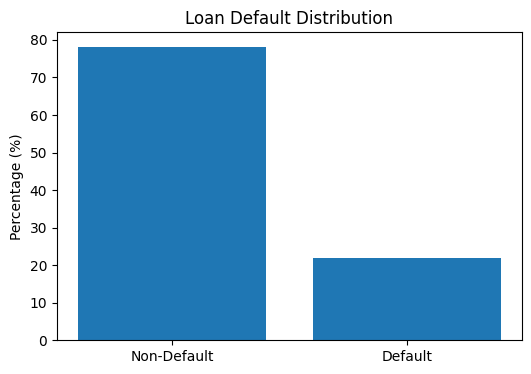

1. Overall Default Rate:
loan_status
0    78.13117
1    21.86883
Name: proportion, dtype: float64


In [91]:
#  Default Distribution
default_pct = df["loan_status"].value_counts(normalize=True).sort_index() * 100

plt.figure(figsize=(6, 4))
plt.bar(["Non-Default", "Default"], default_pct)
plt.ylabel("Percentage (%)")
plt.title("Loan Default Distribution")
plt.show()

print("1. Overall Default Rate:")
print(default_pct)

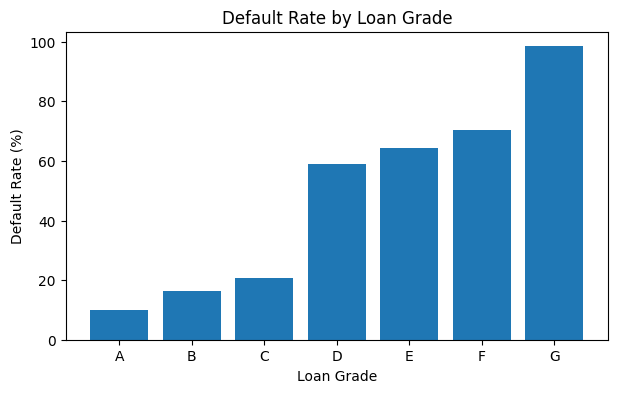

In [92]:

#  Default Rate by Loan Grade
grade_default = (
    df.groupby("loan_grade")["loan_status"].mean().mul(100)
)

plt.figure(figsize=(7, 4))
plt.bar(grade_default.index, grade_default.values)
plt.xlabel("Loan Grade")
plt.ylabel("Default Rate (%)")
plt.title("Default Rate by Loan Grade")
plt.show()

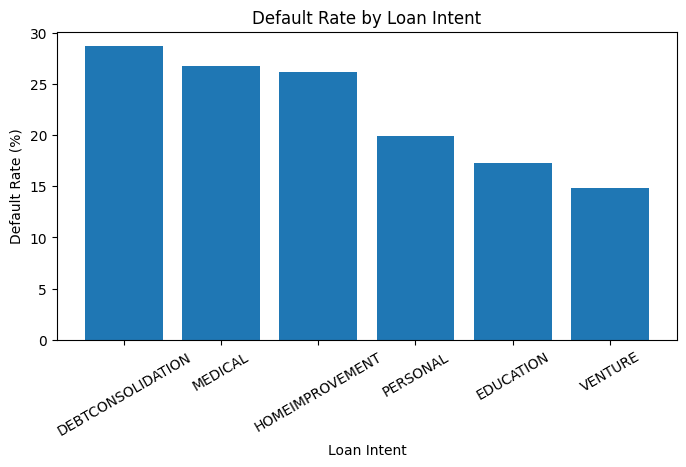

In [93]:
# Default Rate by Loan Intent
intent_default = (
    df.groupby("loan_intent")["loan_status"].mean().mul(100).sort_values(ascending=False)
)

plt.figure(figsize=(8, 4))
plt.bar(intent_default.index, intent_default.values)
plt.xlabel("Loan Intent")
plt.ylabel("Default Rate (%)")
plt.title("Default Rate by Loan Intent")
plt.xticks(rotation=30)
plt.show()


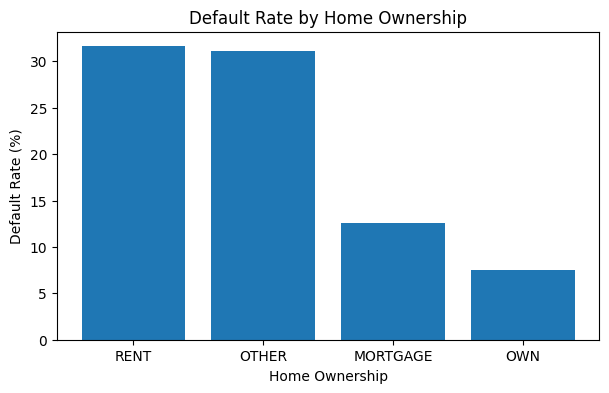

In [94]:
# Default Rate by Home Ownership
home_default = (
    df.groupby("home_ownership")["loan_status"].mean().mul(100).sort_values(ascending=False)
)

plt.figure(figsize=(7, 4))
plt.bar(home_default.index, home_default.values)
plt.xlabel("Home Ownership")
plt.ylabel("Default Rate (%)")
plt.title("Default Rate by Home Ownership")
plt.show()

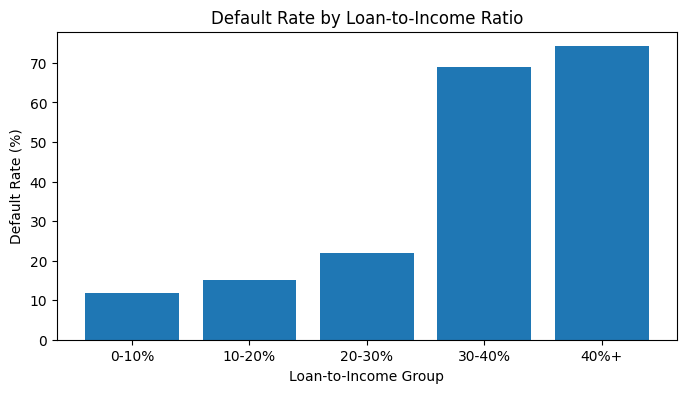

In [95]:
#  Default Rate by Loan-to-Income Group
loan_income_default = (
    df.groupby("loan_income_group", observed=True)["loan_status"].mean().mul(100)
)

plt.figure(figsize=(8, 4))
plt.bar(loan_income_default.index.astype(str), loan_income_default.values)
plt.xlabel("Loan-to-Income Group")
plt.ylabel("Default Rate (%)")
plt.title("Default Rate by Loan-to-Income Ratio")
plt.show()


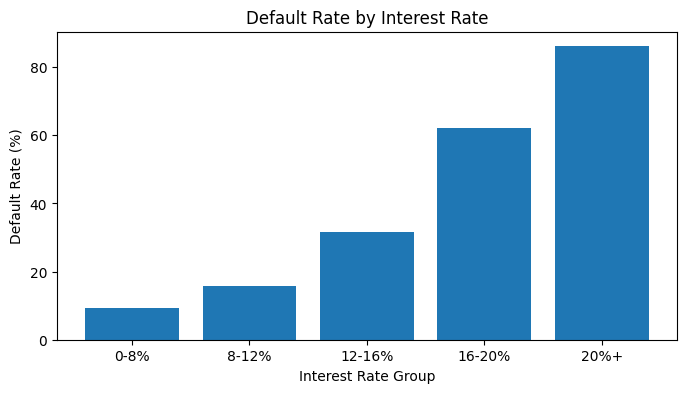

In [96]:


#  Default Rate by Interest Rate Group
interest_default = (
    df.groupby("interest_rate_group", observed=True)["loan_status"].mean().mul(100)
)

plt.figure(figsize=(8, 4))
plt.bar(interest_default.index.astype(str), interest_default.values)
plt.xlabel("Interest Rate Group")
plt.ylabel("Default Rate (%)")
plt.title("Default Rate by Interest Rate")
plt.show()


# 10. Key Findings

- The overall loan default rate is **21.87%**.
- Default rates increase substantially across lower-quality loan grades.
- Default rates vary across different loan purposes.
- Renters show a higher observed default rate than borrowers who own homes or have a mortgage.
- Higher loan-to-income groups show substantially higher observed default rates.
- Higher interest-rate groups show substantially higher observed default rates.

> These findings describe patterns observed in the dataset; they should not be interpreted as proof of causation.

# 11. Business Recommendations

1. **Use loan grade as an important risk-monitoring factor.**
2. **Conduct additional affordability checks for loans with high loan-to-income ratios.**
3. **Closely monitor higher-interest-rate loan segments.**
4. **Include loan intent as an additional dimension in portfolio risk analysis.**
5. **Consider home ownership as a contextual variable when evaluating observed default patterns.**
6. **Use multiple borrower and loan characteristics together rather than relying on a single variable for risk assessment.**

These recommendations are based on the observed patterns in this dataset and should be validated further before being used for operational lending decisions.

# 12. Conclusion

The analysis cleaned and validated the loan dataset, explored borrower and loan characteristics, examined default patterns, and translated the main findings into business recommendations.

The next stage of the project can use these results to build a **Power BI dashboard** for stakeholder reporting.

In [99]:
df.to_csv('Loan_Default_Risk_Analysis_Cleaned', index=False)